# Optimización definitiva de Crop4

Se optimiza Crop4 primero en Fashion-MNIST y luego en MNIST, maximizando primero `acc_both` y luego `ssim`. Cada estudio usa 100 pruebas de 30 iteraciones, con un lote fijo de 1.000 mezclas de entrenamiento y semilla 3333.

Crop4 usa el mismo CVAE y predictor que Crop2 y Crop3. Se ajustan `delta`, `confidence_scale` y `confidence_floor` con los rangos del experimento previo de Crop4. Se fijan `bias = 0.22` y `slope = 22`, como en el experimento definitivo de Crop2 y Crop3.

Los estudios y las curvas de Crop2 y Crop3 se cargan desde `results/<dataset>/<objetivo>/`. Para cada corrida de prueba, Crop4 usa los índices, la semilla y la cantidad de iteraciones de las corridas guardadas. Sus estudios, curvas y gráficos de comparación se guardan en `results_crop4/<dataset>/<objetivo>/`.

## Configuración y evaluación

In [3]:
from pathlib import Path
from tempfile import NamedTemporaryFile
import json
import sys

import numpy as np
import optuna

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "project" / "CROP" / "models").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Abrí el notebook desde el repositorio.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

EXPERIMENTS_DIR = PROJECT_ROOT / "project" / "definitive_experiments"
BASELINE_DIR = EXPERIMENTS_DIR / "results"
RESULTS_DIR = EXPERIMENTS_DIR / "results_crop4"
SEED = 3333
LAT, INTER = 64, 256
N_IMAGES = 1000
N_TRIALS = 100
STUDY_ITERATIONS = 30

DATASETS = {"fashion": "Fashion-MNIST", "mnist": "MNIST"}
BASELINE_MODELS = ("Crop2", "Crop3")
SEARCH_SPACE = {
    "delta": [0.0, 1.0, False],
    "confidence_scale": [0.01, 1.0, True],
    "confidence_floor": [0.01, 1.0, True],
}
FIXED_PARAMS = {
    "alpha_1": -2,
    "alpha_2": -22,
    "bias": 0.22,
    "slope": 22,
    "alpha_mix": 0.5,
    "beta": 1,
}
CURVE_KEYS = {"acc_both": "acc_both_plot", "ssim": "ssim_plot", "psnr": "psnr_plot"}


def result_dir(dataset, objective_metric):
    return RESULTS_DIR / dataset / objective_metric


def load_inputs(dataset):
    import tensorflow as tf
    from project.CROP.models.crop4 import Crop4
    from project.loader import Loader

    tf.keras.utils.set_random_seed(SEED)
    return (
        Loader.data(dataset),
        Loader.cvae(model_name=f"int_{INTER}_lat_{LAT}_{dataset}.keras"),
        Loader.predictor(dataset=dataset),
        Crop4,
    )


def sample_training_batch(data):
    split, seed = "train", SEED
    rng = np.random.default_rng(seed)
    x0, x1 = data[f"x_{split}"], data[f"x_{split}_1"]
    y0, y1 = data[f"y_{split}"], data[f"y_{split}_1"]
    idx0 = rng.choice(len(x0), size=N_IMAGES, replace=False)
    idx1 = rng.choice(len(x1), size=N_IMAGES, replace=False)
    return x0[idx0], x1[idx1], y0[idx0], y1[idx1]


def evaluate(inputs, batch, tuned_params, seed, iterations, *, curves=False):
    import tensorflow as tf

    data, cvae, predictor, model_class = inputs
    tf.keras.utils.set_random_seed(seed)
    model = model_class(cvae=cvae, predictor=predictor)
    return model.unmix(
        *batch,
        params={**FIXED_PARAMS, **tuned_params},
        iterations=iterations,
        labels=data["labels"],
        show_image=False,
        show_metrics=False,
        save_all_curves=curves,
    )


def scalar_metric(metrics, key):
    value = metrics[key]
    return float(value[0] if isinstance(value, (tuple, list)) else value)

## Estudios y gráficos de cortes

In [2]:
def study_location(root, dataset, objective_metric, model_name):
    path = root / dataset / objective_metric / f"{model_name}.sqlite3"
    name = f"{dataset}_{objective_metric}_{model_name}"
    return path, f"sqlite:///{path.as_posix()}", name


def load_study(root, dataset, objective_metric, model_name):
    path, storage, name = study_location(root, dataset, objective_metric, model_name)
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró el estudio en {path}")
    return optuna.load_study(storage=storage, study_name=name)


def optimize_crop4(dataset, objective_metric, inputs, train_batch):
    path, storage, name = study_location(RESULTS_DIR, dataset, objective_metric, "Crop4")
    path.parent.mkdir(parents=True, exist_ok=True)
    study = optuna.create_study(
        storage=storage,
        study_name=name,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        load_if_exists=True,
    )
    config = {
        "seed": SEED,
        "images": N_IMAGES,
        "iterations": STUDY_ITERATIONS,
        "latent_dim": LAT,
        "intermediate_dim": INTER,
        "fixed_params": FIXED_PARAMS,
        "search_space": SEARCH_SPACE,
    }
    saved_config = study.user_attrs.get("config")
    if saved_config is None and not study.get_trials(deepcopy=False):
        study.set_user_attr("config", config)
    elif saved_config != config:
        raise ValueError(f"La configuración guardada en {path} difiere de la actual.")

    def objective(trial):
        params = {
            key: trial.suggest_float(key, low, high, log=log)
            for key, (low, high, log) in SEARCH_SPACE.items()
        }
        metrics = evaluate(inputs, train_batch, params, SEED, STUDY_ITERATIONS)
        score = scalar_metric(metrics, objective_metric)
        if not np.isfinite(score):
            raise ValueError(f"Métrica no finita en {name}: {score}")
        trial.set_user_attr("effective_params", {**FIXED_PARAMS, **params})
        for key in ("acc_both", "ssim", "recon_bpsnr"):
            value = scalar_metric(metrics, key)
            trial.set_user_attr(key, value if np.isfinite(value) else None)
        return score

    completed = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,), deepcopy=False)
    remaining = max(0, N_TRIALS - len(completed))
    if remaining:
        study.optimize(objective, n_trials=remaining, n_jobs=1)

    print(f"{name} · {study.best_value:.6g} · {study.best_params}", flush=True)
    return study


def plot_study(study, dataset, objective_metric):
    from optuna.visualization import plot_slice

    fig = plot_slice(study, params=list(SEARCH_SPACE),
                     target_name=objective_metric)
    fig.update_layout(title=f"{DATASETS[dataset]} · Crop4 · {objective_metric}")
    fig.show()

## Comparación con Crop2 y Crop3

In [4]:
def load_baseline(dataset, objective_metric):
    studies = {
        model: load_study(BASELINE_DIR, dataset, objective_metric, model)
        for model in BASELINE_MODELS
    }
    best_trials = {model: study.best_trial.number for model, study in studies.items()}
    best_params = {model: study.best_params for model, study in studies.items()}
    study_configs = {model: study.user_attrs["config"] for model, study in studies.items()}
    folder = BASELINE_DIR / dataset / objective_metric / (
        f"comparison_Crop2_{best_trials['Crop2']}_Crop3_{best_trials['Crop3']}"
    )

    first_path = folder / "run_01.npz"
    with np.load(first_path, allow_pickle=False) as saved:
        config = json.loads(saved["config"].item())
    if (config["best_trials"] != best_trials or config["best_params"] != best_params
            or config["study_configs"] != study_configs):
        raise ValueError(f"Los estudios y las corridas guardadas difieren en {folder}.")
    for study_config in study_configs.values():
        if (study_config["latent_dim"], study_config["intermediate_dim"],
                study_config["fixed_params"]["alpha_mix"]) != (LAT, INTER, FIXED_PARAMS["alpha_mix"]):
            raise ValueError(f"El CVAE o el peso de mezcla difieren en {folder}.")

    runs = []
    for number in range(1, config["runs"] + 1):
        path = folder / f"run_{number:02d}.npz"
        with np.load(path, allow_pickle=False) as saved:
            if json.loads(saved["config"].item()) != config:
                raise ValueError(f"La configuración difiere en {path}.")
            runs.append({
                "seed": int(saved["seed"].item()),
                "source1_indices": saved["source1_indices"],
                "source2_indices": saved["source2_indices"],
                "curves": read_curves(saved, BASELINE_MODELS, config["iterations"], path),
            })
    return config, runs


def read_curves(saved, models, iterations, path):
    curves = {}
    for model in models:
        curves[model] = {}
        for metric in CURVE_KEYS:
            values = saved[f"{model}_{metric}"]
            if values.shape != (iterations,):
                raise ValueError(f"Cantidad de iteraciones incorrecta para {model} y {metric} en {path}.")
            curves[model][metric] = values
    return curves


def comparison_config(baseline_config, study):
    return {
        **baseline_config,
        "study_configs": {**baseline_config["study_configs"], "Crop4": study.user_attrs["config"]},
        "best_trials": {**baseline_config["best_trials"], "Crop4": study.best_trial.number},
        "best_params": {**baseline_config["best_params"], "Crop4": study.best_params},
    }


def comparison_dir(dataset, objective_metric, config):
    trials = config["best_trials"]
    return result_dir(dataset, objective_metric) / (
        f"comparison_Crop2_{trials['Crop2']}_Crop3_{trials['Crop3']}_Crop4_{trials['Crop4']}"
    )


def read_crop4_run(path, config, reference):
    with np.load(path, allow_pickle=False) as saved:
        if json.loads(saved["config"].item()) != config:
            raise ValueError(f"La configuración difiere en {path}.")
        if any(not np.array_equal(saved[key], reference[key])
               for key in ("seed", "source1_indices", "source2_indices")):
            raise ValueError(f"La semilla o los índices del lote difieren en {path}.")
        return read_curves(saved, ("Crop4",), config["iterations"], path)


def run_comparison(dataset, objective_metric, config, baseline_runs, inputs):
    folder = comparison_dir(dataset, objective_metric, config)
    folder.mkdir(parents=True, exist_ok=True)
    data = inputs[0]
    for number, reference in enumerate(baseline_runs, start=1):
        path = folder / f"run_{number:02d}.npz"
        if path.is_file():
            read_crop4_run(path, config, reference)
            continue

        idx0, idx1 = reference["source1_indices"], reference["source2_indices"]
        batch = (data["x_test"][idx0], data["x_test_1"][idx1],
                 data["y_test"][idx0], data["y_test_1"][idx1])
        print(f"{DATASETS[dataset]} · {objective_metric} · corrida {number}/{config['runs']}",
              flush=True)
        metrics = evaluate(inputs, batch, config["best_params"]["Crop4"],
                           reference["seed"], config["iterations"], curves=True)
        arrays = {
            "config": json.dumps(config),
            "seed": reference["seed"],
            "source1_indices": idx0,
            "source2_indices": idx1,
            **{f"Crop4_{metric}": np.asarray(metrics[key], dtype=float)
               for metric, key in CURVE_KEYS.items()},
        }
        read_curves(arrays, ("Crop4",), config["iterations"], path)
        with NamedTemporaryFile(dir=folder, suffix=".tmp", delete=False) as temporary:
            temp_path = Path(temporary.name)
            try:
                np.savez_compressed(temporary, **arrays)
                temporary.close()
                temp_path.replace(path)
            finally:
                temporary.close()
                temp_path.unlink(missing_ok=True)


def load_comparison(dataset, objective_metric, config, baseline_runs):
    folder = comparison_dir(dataset, objective_metric, config)
    runs = [
        {**reference["curves"],
         **read_crop4_run(folder / f"run_{number:02d}.npz", config, reference)}
        for number, reference in enumerate(baseline_runs, start=1)
    ]
    return {
        model: {metric: np.stack([run[model][metric] for run in runs])
                for metric in CURVE_KEYS}
        for model in (*BASELINE_MODELS, "Crop4")
    }

In [5]:
def plot_comparison(dataset, objective_metric, config, curves):
    import matplotlib.pyplot as plt

    folder = comparison_dir(dataset, objective_metric, config)
    footer = "\n".join(
        f"{model} · " + " | ".join(f"{name} = {value:.6g}" for name, value in params.items())
        for model, params in config["best_params"].items()
    )
    labels = {
        "acc_both": ("Exactitud de ambas fuentes", "Exactitud [%]", 100),
        "ssim": ("SSIM", "SSIM", 1),
        "psnr": ("PSNR", "PSNR [dB]", 1),
    }
    for metric, (title, ylabel, scale) in labels.items():
        fig, ax = plt.subplots(figsize=(9, 6))
        for model, model_curves in curves.items():
            values = model_curves[metric] * scale
            mean, std = values.mean(axis=0), values.std(axis=0)
            iterations = np.arange(1, len(mean) + 1)
            line, = ax.plot(iterations, mean, label=model)
            ax.fill_between(iterations, mean - std, mean + std,
                            color=line.get_color(), alpha=0.2)

        ax.set_title(
            f"{DATASETS[dataset]} · {title} · {config['runs']} corridas\n"
            f"Parámetros optimizados con {objective_metric}"
        )
        ax.set_xlabel("Iteración")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend()
        fig.text(0.5, 0.02, footer, ha="center", va="bottom", fontsize=8)
        fig.tight_layout(rect=(0, 0.14, 1, 1))
        fig.savefig(folder / f"{metric}.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)



def run_experiment(dataset, objective_metric):
    baseline_config, baseline_runs = load_baseline(dataset, objective_metric)
    inputs = load_inputs(dataset)
    train_batch = sample_training_batch(inputs[0])
    study = optimize_crop4(dataset, objective_metric, inputs, train_batch)
    plot_study(study, dataset, objective_metric)

    config = comparison_config(baseline_config, study)
    run_comparison(dataset, objective_metric, config, baseline_runs, inputs)
    curves = load_comparison(dataset, objective_metric, config, baseline_runs)
    plot_comparison(dataset, objective_metric, config, curves)

## Fashion-MNIST

I0000 00:00:1795631242.401917  413539 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795631242.542222  413539 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795631244.794765  413539 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Usando fashion como dataset


I0000 00:00:1795631246.851928  413539 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9534 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6
[I 2026-11-25 15:27:28,457] A new study created in RDB with name: fashion_acc_both_Crop4
I0000 00:00:1795631249.059022  413539 cuda_dnn.cc:461] Loaded cuDNN version 92801
[I 2026-11-25 15:27:32,583] Trial 0 finished with value: 0.68 and parameters: {'delta': 0.7515756072044787, 'confidence_scale': 0.01653874498578343, 'confidence_floor': 0.09380857915942345}. Best is trial 0 with value: 0.68.
[I 2026-11-25 15:27:34,211] Trial 1 finished with value: 0.684 and parameters: {'delta': 0.4998311777480342, 'confidence_scale': 0.20616740190582394, 'confidence_floor': 0.02963257706116777}. Best is trial 1 with value: 0.684.
[I 2026-11-25 15:27:35,785] Trial 2 finished with value: 0.675 and parameters: {'delta': 0.6127948906605941, 'confidence_scale': 0.01735021

fashion_acc_both_Crop4 · 0.707 · {'delta': 0.46017548446173967, 'confidence_scale': 0.010388421833236443, 'confidence_floor': 0.0206388992941037}


Fashion-MNIST · acc_both · corrida 1/10
Fashion-MNIST · acc_both · corrida 2/10
Fashion-MNIST · acc_both · corrida 3/10
Fashion-MNIST · acc_both · corrida 4/10
Fashion-MNIST · acc_both · corrida 5/10
Fashion-MNIST · acc_both · corrida 6/10
Fashion-MNIST · acc_both · corrida 7/10
Fashion-MNIST · acc_both · corrida 8/10
Fashion-MNIST · acc_both · corrida 9/10
Fashion-MNIST · acc_both · corrida 10/10


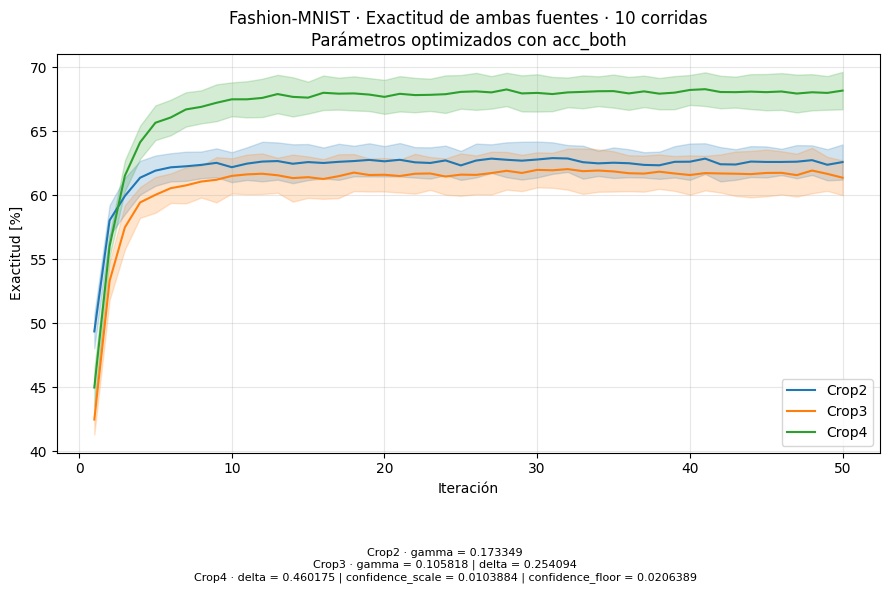

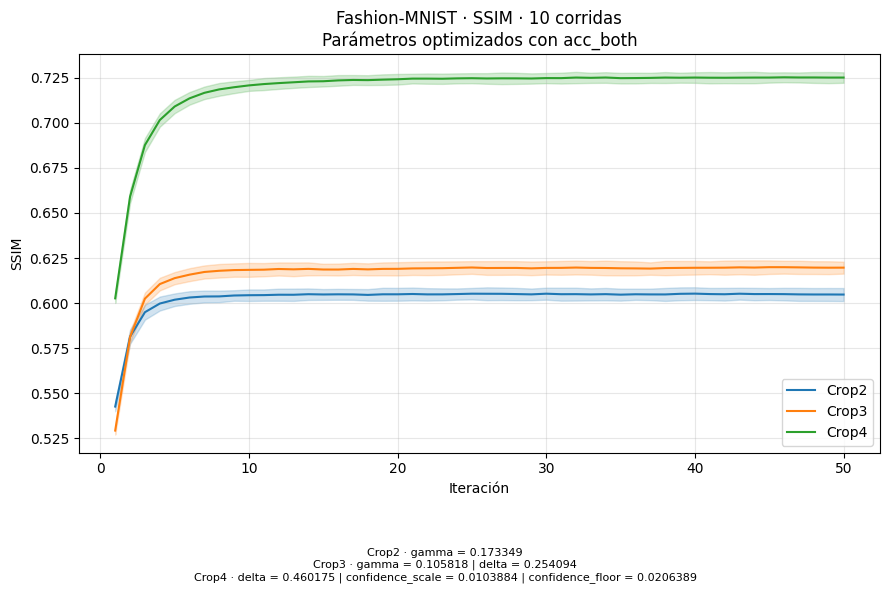

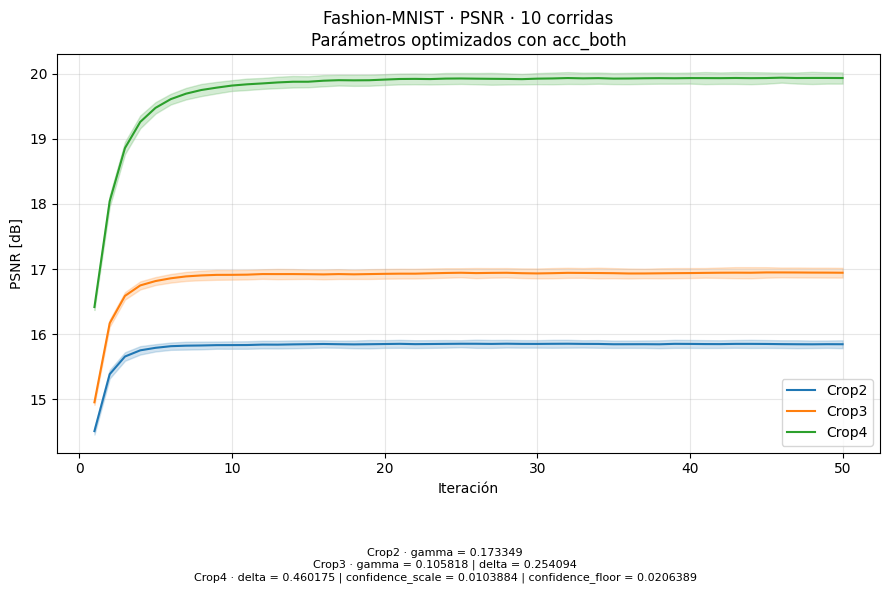

In [6]:
run_experiment("fashion", "acc_both")

Usando fashion como dataset


[I 2026-11-25 15:32:54,494] A new study created in RDB with name: fashion_ssim_Crop4
[I 2026-11-25 15:32:56,190] Trial 0 finished with value: 0.7279758453369141 and parameters: {'delta': 0.7515756072044787, 'confidence_scale': 0.01653874498578343, 'confidence_floor': 0.09380857915942345}. Best is trial 0 with value: 0.7279758453369141.
[I 2026-11-25 15:32:57,815] Trial 1 finished with value: 0.7164160013198853 and parameters: {'delta': 0.4998311777480342, 'confidence_scale': 0.20616740190582394, 'confidence_floor': 0.02963257706116777}. Best is trial 0 with value: 0.7279758453369141.
[I 2026-11-25 15:32:59,461] Trial 2 finished with value: 0.7161345481872559 and parameters: {'delta': 0.6127948906605941, 'confidence_scale': 0.017350212840849595, 'confidence_floor': 0.26570797725119155}. Best is trial 0 with value: 0.7279758453369141.
[I 2026-11-25 15:33:01,137] Trial 3 finished with value: 0.7109968662261963 and parameters: {'delta': 0.37256054205032785, 'confidence_scale': 0.1120821738

fashion_ssim_Crop4 · 0.739437 · {'delta': 0.773827580350527, 'confidence_scale': 0.017921577088014545, 'confidence_floor': 0.019927047602456276}


Fashion-MNIST · ssim · corrida 1/10
Fashion-MNIST · ssim · corrida 2/10
Fashion-MNIST · ssim · corrida 3/10
Fashion-MNIST · ssim · corrida 4/10
Fashion-MNIST · ssim · corrida 5/10
Fashion-MNIST · ssim · corrida 6/10
Fashion-MNIST · ssim · corrida 7/10
Fashion-MNIST · ssim · corrida 8/10
Fashion-MNIST · ssim · corrida 9/10
Fashion-MNIST · ssim · corrida 10/10


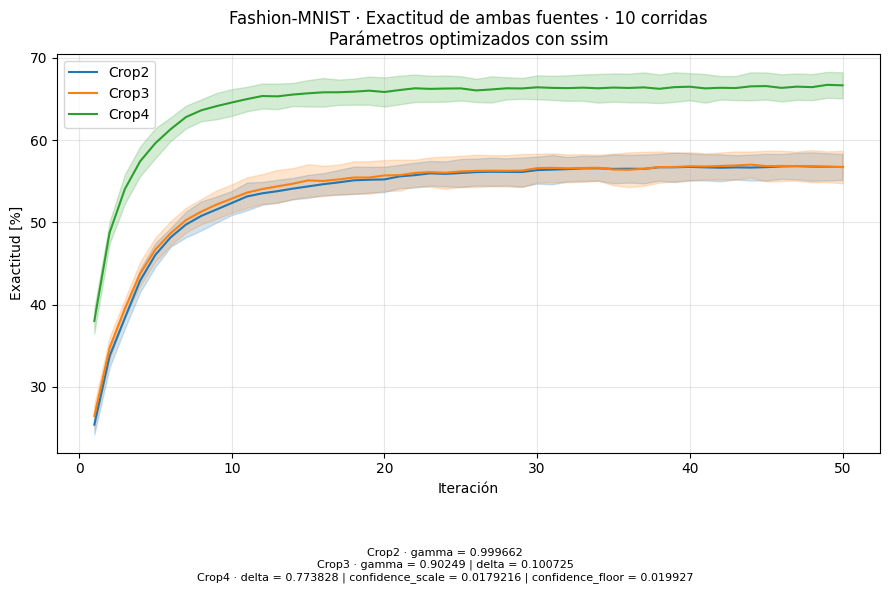

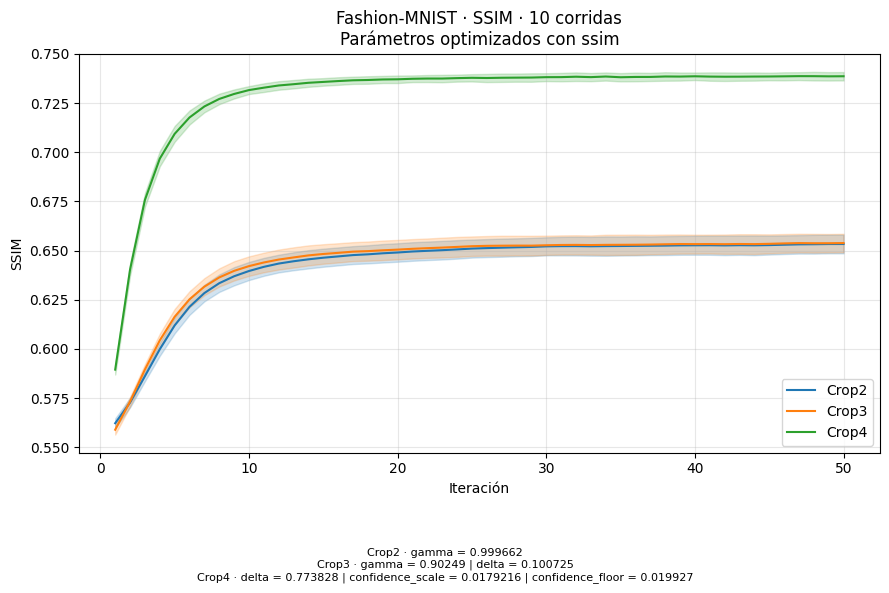

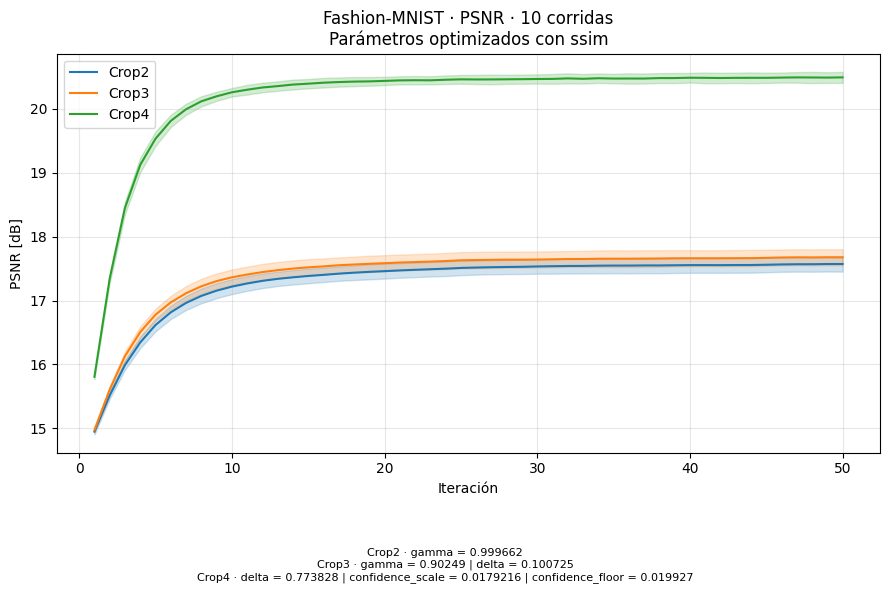

In [7]:
run_experiment("fashion", "ssim")

## MNIST

In [ ]:
run_experiment("mnist", "acc_both")

In [ ]:
run_experiment("mnist", "ssim")

## Recuperar resultados guardados

Ejecutá primero las celdas de configuración y funciones. Elegí el dataset y la métrica objetivo para volver a generar los gráficos a partir de las corridas guardadas. Las bandas muestran la media ± un desvío estándar entre corridas.

In [ ]:
dataset, objective_metric = "fashion", "acc_both"

baseline_config, baseline_runs = load_baseline(dataset, objective_metric)
study = load_study(RESULTS_DIR, dataset, objective_metric, "Crop4")
print(f"Crop4 · {study.best_value:.6g} · {study.best_params}")
plot_study(study, dataset, objective_metric)

config = comparison_config(baseline_config, study)
curves = load_comparison(dataset, objective_metric, config, baseline_runs)
plot_comparison(dataset, objective_metric, config, curves)